In [ ]:
# ASSIGNMENT 3 - PART B

In [1]:

import os, re, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

In [2]:
# Q1

uploaded = files.upload()
b_file = next(
    (f for f in uploaded if "dashmart" in f.lower() and f.lower().endswith(".csv")),
    None
)
if b_file is None:
    raise ValueError("Upload dashmart_delivery_times_raw.csv")

raw = pd.read_csv(b_file, dtype=str, keep_default_na=False)

print("Shape:", raw.shape)
print("Columns:", [repr(c) for c in raw.columns])
for c in ["order_hour", "distance_km", "delivery_minutes"]:
    print(f"\nDistinct raw values/examples for {c}:")
    print(raw[c].drop_duplicates().head(25).tolist())

Saving dashmart_delivery_times_raw.csv to dashmart_delivery_times_raw.csv
Shape: (2430, 11)
Columns: ["'order_id'", "'store'", "'order_hour'", "'distance_km'", "'items'", "'order_value_rs'", "'store_queue'", "'raining'", "'rider_experience_months'", "'drop_floor'", "'delivery_minutes'"]

Distinct raw values/examples for order_hour:
['14', '22:00', '18', '17', '9', '22', '20:00', '21', '23', '20', '16', '19', '2 PM', '8', '10', '11', '12 AM', '12 PM', '2 AM', '13', '12', '0', '14:00', '19:00', '1 PM']

Distinct raw values/examples for distance_km:
['0.74', '0.9 km', '1.84', '1.11', '210 m', '0.3 km', '690 m', '1.31', '1.33', '2.44 km', '1.76', '0.76', '1.03 km', '1.3', '1.16', '990 m', '2.87', '1.52', '1.01', '0.25 km', '2.42', '0.77 km', '1.54', '590 m', '0.37']

Distinct raw values/examples for delivery_minutes:
['6.3', '13.1', '17.0', '13.2', '8.0', '11.8', '19.1', '14.2', '23.5', '21.5', '8.3', '14.4 min', '17.6', '9.4', '14.7', '19.4', '18.4 min', '12.2', '6.8', '19.5', '14.0', '15

In [3]:
# Q2
df = raw.copy()
df["store"] = df["store"].astype(str).str.strip().str.lower().str.replace(
    r"\s+", "", regex=True
)
df["store"] = df["store"].str.replace("dm-", "DM-", regex=False).str.title()
# Restore desired store-name casing
df["store"] = df["store"].str.replace("Dm-", "DM-", regex=False)

def parse_hour(value):
    s = str(value).strip().upper()
    if not s:
        return np.nan
    # 8 PM, 12 AM, 12 PM
    match = re.fullmatch(r"(\d{1,2})\s*(AM|PM)", s)
    if match:
        h = int(match.group(1))
        ampm = match.group(2)
        if not 1 <= h <= 12:
            return np.nan
        if ampm == "AM":
            return 0 if h == 12 else h
        return 12 if h == 12 else h + 12
    # 20, 20:00, 8:00
    match = re.fullmatch(r"(\d{1,2})(?::\d{1,2})?", s)
    if match:
        h = int(match.group(1))
        return h if 0 <= h <= 23 else np.nan
    return np.nan

df["order_hour"] = df["order_hour"].apply(parse_hour)

print(df[["store", "order_hour"]].head(15).to_string(index=False))
print("8 PM ->", parse_hour("8 PM"))
print("12 AM ->", parse_hour("12 AM"))
print("Unique stores:", sorted(df["store"].unique()))

      store  order_hour
  DM-Panvel          14
DM-Kharghar          22
   DM-Nerul          18
  DM-Panvel          17
  DM-Panvel           9
   DM-Nerul          22
DM-Kharghar          20
   DM-Nerul          14
DM-Kharghar          21
  DM-Panvel          23
   DM-Nerul          23
   DM-Nerul          22
   DM-Nerul          18
  DM-Panvel          20
   DM-Nerul          16
8 PM -> 20
12 AM -> 0
Unique stores: ['DM-Kharghar', 'DM-Nerul', 'DM-Panvel', 'DM-Vashi', 'Dmkharghar', 'Dmnerul', 'Dmpanvel', 'Dmvashi']


In [4]:
# Q3
def parse_distance(value):
    s = str(value).strip().lower().replace(",", "")
    if s in {"", "?", "na", "n/a", "not measured"}:
        return np.nan
    m = re.fullmatch(r"(-?\d+(?:\.\d+)?)\s*(km|m)?", s)
    if not m:
        return np.nan
    value_num = float(m.group(1))
    unit = m.group(2)
    if unit == "m":
        value_num /= 1000
    return value_num


distance_examples = df["distance_km"].head(5).copy()
df["distance_km"] = df["distance_km"].apply(parse_distance)
print(pd.DataFrame({
    "Before": distance_examples,
    "After_km": df.loc[distance_examples.index, "distance_km"]
}).to_string(index=False))

Before  After_km
  0.74      0.74
0.9 km      0.90
  1.84      1.84
  1.11      1.11
 210 m      0.21


In [5]:
# Q4
def parse_minutes(value):
    s = str(value).strip().lower()
    if s in {"", "?", "na", "n/a", "not measured"}:
        return np.nan
    s = s.replace(" ", "")
    if s.endswith("min"):
        s = s[:-3]
    # h:mm:ss -> decimal minutes
    if re.fullmatch(r"\d+:\d{1,2}:\d{1,2}", s):
        h, m, sec = map(int, s.split(":"))
        return h*60 + m + sec/60
    try:
        return float(s)
    except ValueError:
        return np.nan

df["delivery_minutes"] = df["delivery_minutes"].apply(parse_minutes)

print(df["delivery_minutes"].describe().to_string())
# Rule: non-positive or over 120 minutes considered impossible/reopened records
impossible = (
    df["delivery_minutes"].notna() &
    ((df["delivery_minutes"] <= 0) | (df["delivery_minutes"] > 120))
)
print("Impossible delivery times:", int(impossible.sum()))
print("Example impossible rows:")
print(df.loc[impossible, ["order_id", "delivery_minutes"]].head(10).to_string(index=False))
df = df.loc[~impossible].copy()
print("Rows after removing impossible times:", len(df))
print("Interpretation: these records are not plausible completed delivery durations, so they are excluded rather than guessed or rewritten.")


count    2430.000000
mean       17.404733
std        58.027330
min        -5.000000
25%        11.500000
50%        14.200000
75%        17.300000
max      1440.000000
Impossible delivery times: 9
Example impossible rows:
 order_id  delivery_minutes
DMO700646              -5.0
DMO701295              -5.0
DMO701976               0.0
DMO700195            1440.0
DMO700756             987.5
DMO701688            1440.0
DMO701526             412.0
DMO701557             987.5
DMO701489            1440.0
Rows after removing impossible times: 2421
Interpretation: these records are not plausible completed delivery durations, so they are excluded rather than guessed or rewritten.


In [6]:
# Q5
def parse_number(value):
    s = str(value).strip().replace(",", "").replace("₹", "")
    if s.lower() in {"", "?", "na", "n/a", "not measured"}:
        return np.nan
    return pd.to_numeric(s, errors="coerce")

df["order_value_rs"] = df["order_value_rs"].apply(parse_number)
df["store_queue"] = df["store_queue"].apply(parse_number)
df["items"] = df["items"].apply(parse_number)
df["drop_floor"] = df["drop_floor"].apply(parse_number)
df["rider_experience_months"] = df["rider_experience_months"].apply(
    lambda x: 0 if str(x).strip().lower() == "new joiner" else parse_number(x)
)
rain = df["raining"].astype(str).str.strip().str.lower()
df["raining"] = rain.map({
    "y": 1, "yes": 1, "1": 1, "true": 1,
    "n": 0, "no": 0, "0": 0, "false": 0
})
before = len(df)
df = df.drop_duplicates().copy()

print("Rows before duplicate removal:", before)
print("Rows after duplicate removal:", len(df))
print("Duplicates removed:", before-len(df))
print("Rain values:", df["raining"].value_counts(dropna=False).to_dict())

Rows before duplicate removal: 2421
Rows after duplicate removal: 2391
Duplicates removed: 30
Rain values: {0: 1886, 1: 505}


In [7]:
# Q6
print(df.isna().sum().sort_values(ascending=False).to_string())
clean_b_path = "/content/dashmart_delivery_times_cleaned.csv"
df.to_csv(clean_b_path, index=False)
print("Cleaned CSV saved:", clean_b_path)
print("Use median imputation inside the pipeline, fitted only on training folds.")

rider_experience_months    43
store_queue                40
order_id                    0
order_hour                  0
store                       0
items                       0
distance_km                 0
order_value_rs              0
raining                     0
drop_floor                  0
delivery_minutes            0
Cleaned CSV saved: /content/dashmart_delivery_times_cleaned.csv
Use median imputation inside the pipeline, fitted only on training folds.


count    2391.000000
mean       14.700627
std         4.574722
min         5.000000
25%        11.500000
50%        14.100000
75%        17.300000
max        34.700000
Median: 14.1
Mean: 14.7
Median later than 15 minutes: -0.9 minutes
Share breaking 15-minute promise: 41.74 %


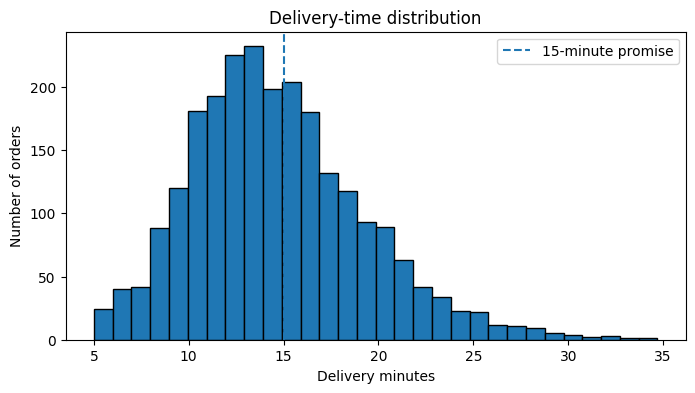

In [8]:
# Q7 - Describe delivery times, histogram, late share

print(df["delivery_minutes"].describe().to_string())
median_time = df["delivery_minutes"].median()
mean_time = df["delivery_minutes"].mean()
late15 = (df["delivery_minutes"] > 15).mean()
print("Median:", round(median_time, 2))
print("Mean:", round(mean_time, 2))
print("Median later than 15 minutes:", round(median_time-15, 2), "minutes")
print("Share breaking 15-minute promise:", round(late15*100, 2), "%")

plt.figure(figsize=(8, 4))
plt.hist(df["delivery_minutes"].dropna(), bins=30, edgecolor="black")
plt.axvline(15, linestyle="--", label="15-minute promise")
plt.xlabel("Delivery minutes")
plt.ylabel("Number of orders")
plt.title("Delivery-time distribution")
plt.legend()
plt.show()

In [9]:
# Prepare data
features = [
    "distance_km", "items", "order_value_rs", "store_queue",
    "raining", "rider_experience_months", "drop_floor", "order_hour"
]
model_df = df.dropna(subset=["delivery_minutes"]).copy()
X = model_df[features].replace([np.inf, -np.inf], np.nan)
y = model_df["delivery_minutes"].astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.20, random_state=42
)

def reg_metrics(y_true, pred):
    return {
        "MAE": mean_absolute_error(y_true, pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
        "R2": r2_score(y_true, pred)
    }

def make_regressor(scaler=None, k=7, weights="uniform", feature_list=None):
    if feature_list is None:
        feature_list = features
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scaler is not None:
        steps.append(("scaler", scaler))
    steps.append(("knn", KNeighborsRegressor(
        n_neighbors=k, weights=weights
    )))
    return Pipeline(steps)

In [10]:
# Q8

baseline_prediction = np.repeat(y_train.median(), len(y_test))
baseline_metrics = reg_metrics(y_test, baseline_prediction)
print("Training median:", round(y_train.median(), 3))
print(pd.Series(baseline_metrics).round(4).to_string())

Training median: 14.1
MAE     3.5186
RMSE    4.5260
R2     -0.0279


In [11]:
# Q9

raw_model = make_regressor(None, k=7)
raw_model.fit(X_train, y_train)
pred_raw = raw_model.predict(X_test)
metrics_raw = reg_metrics(y_test, pred_raw)
print(pd.Series(metrics_raw).round(4).to_string())
print("Interpretation: a negative R² means predicting the training median would have performed better on this test set.")

MAE     3.7214
RMSE    4.6703
R2     -0.0945
Interpretation: a negative R² means predicting the training median would have performed better on this test set.


In [12]:
# Q10
std_model = make_regressor(StandardScaler(), k=7)
std_model.fit(X_train, y_train)
pred_std = std_model.predict(X_test)
metrics_std = reg_metrics(y_test, pred_std)

minmax_model = make_regressor(MinMaxScaler(), k=7)
minmax_model.fit(X_train, y_train)
pred_minmax = minmax_model.predict(X_test)
metrics_minmax = reg_metrics(y_test, pred_minmax)

print(pd.DataFrame([
    {"Model": "Baseline median", **baseline_metrics},
    {"Model": "Raw KNN", **metrics_raw},
    {"Model": "StandardScaler KNN", **metrics_std},
    {"Model": "MinMaxScaler KNN", **metrics_minmax}
]).set_index("Model").round(4).to_string())
print("Feature ranges:")
print(X_train.agg(["min", "max"]).T.to_string())
print("Interpretation: order_hour has a small range but represents clock time; order_value_rs may dominate raw distances due to its scale.")

                       MAE    RMSE      R2
Model                                     
Baseline median     3.5186  4.5260 -0.0279
Raw KNN             3.7214  4.6703 -0.0945
StandardScaler KNN  1.7264  2.1652  0.7648
MinMaxScaler KNN    1.7731  2.2163  0.7535
Feature ranges:
                          min     max
distance_km               0.2     5.0
items                     1.0    16.0
order_value_rs           60.0  2129.0
store_queue               0.0    21.0
raining                   0.0     1.0
rider_experience_months   0.0    60.0
drop_floor                0.0    29.0
order_hour                0.0    23.0
Interpretation: order_hour has a small range but represents clock time; order_value_rs may dominate raw distances due to its scale.


In [14]:
# Q11

print("MAE is the average absolute error in minutes and matches the typical-error target.")
print("RMSE penalises large mistakes more strongly than MAE.")

MAE is the average absolute error in minutes and matches the typical-error target.
RMSE penalises large mistakes more strongly than MAE.


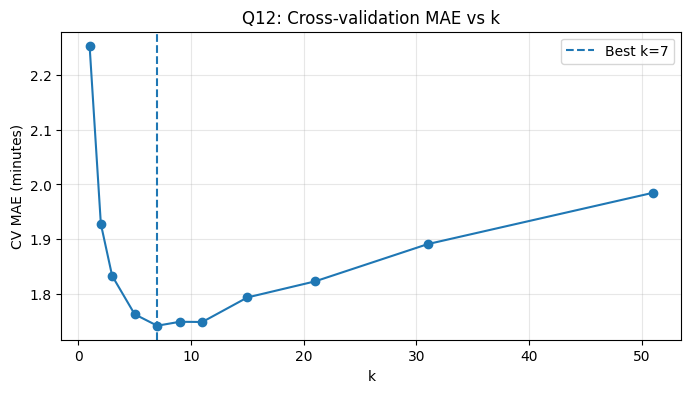

Best k: 7
Best mean CV MAE: 1.7417
k=1 is sensitive to noise; very large k averages dissimilar orders and underfits.


In [15]:
# Q12
ks = [1, 2, 3, 5, 7, 9, 11, 15, 21, 31, 51]
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_maes = []
for k in ks:
    pipe = make_regressor(StandardScaler(), k=k)
    scores = cross_val_score(
        pipe, X_train, y_train, cv=kf,
        scoring="neg_mean_absolute_error", n_jobs=-1
    )
    cv_maes.append(-scores.mean())

best_k12 = ks[int(np.argmin(cv_maes))]
plt.figure(figsize=(8, 4))
plt.plot(ks, cv_maes, marker="o")
plt.axvline(best_k12, linestyle="--", label=f"Best k={best_k12}")
plt.xlabel("k")
plt.ylabel("CV MAE (minutes)")
plt.title("Q12: Cross-validation MAE vs k")
plt.grid(True, alpha=.3)
plt.legend()
plt.show()
print("Best k:", best_k12)
print("Best mean CV MAE:", round(min(cv_maes), 4))
print("k=1 is sensitive to noise; very large k averages dissimilar orders and underfits.")

In [16]:
# Q13
Xcyc = X.copy()
Xcyc["hour_sin"] = np.sin(2*np.pi*Xcyc["order_hour"]/24)
Xcyc["hour_cos"] = np.cos(2*np.pi*Xcyc["order_hour"]/24)
Xcyc = Xcyc.drop(columns=["order_hour"])
cyc_features = [c for c in Xcyc.columns]

Xcyc_train, Xcyc_test, ycyc_train, ycyc_test = train_test_split(
    Xcyc, y, test_size=.20, random_state=42
)
cyc_model = make_regressor(StandardScaler(), k=7, feature_list=cyc_features)
cyc_model.fit(Xcyc_train, ycyc_train)
pred_cyc = cyc_model.predict(Xcyc_test)
print("Linear-hour model MAE:", round(metrics_std["MAE"], 4))
print("Cyclical-hour model MAE:", round(mean_absolute_error(ycyc_test, pred_cyc), 4))

# Compare late-night orders in test data
late_night_mask = model_df.loc[X_test.index, "order_hour"].isin([23, 0, 1])
if late_night_mask.sum():
    print("Linear-hour late-night MAE:",
          round(mean_absolute_error(y_test[late_night_mask], pred_std[late_night_mask]), 4))
    print("Cyclical-hour late-night MAE:",
          round(mean_absolute_error(ycyc_test[late_night_mask], pred_cyc[late_night_mask]), 4))
else:
    print("No late-night orders in the test split.")
print("Interpretation: cyclical encoding helps represent midnight as close to 23:00; whether it improves this dataset must be judged by measured MAE.")

Linear-hour model MAE: 1.7264
Cyclical-hour model MAE: 1.7715
Linear-hour late-night MAE: 1.6922
Cyclical-hour late-night MAE: 1.7608
Interpretation: cyclical encoding helps represent midnight as close to 23:00; whether it improves this dataset must be judged by measured MAE.


In [17]:
# Q14
Xtr, Xte, ytr, yte = train_test_split(
    Xcyc, y, test_size=.20, random_state=42
)
tuned_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor())
])
grid = GridSearchCV(
    tuned_pipe,
    {
        "knn__n_neighbors": [1, 2, 3, 5, 7, 9, 11, 15, 21, 31, 51],
        "knn__weights": ["uniform", "distance"]
    },
    scoring="neg_mean_absolute_error",
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1, refit=True
)
grid.fit(Xtr, ytr)
best_model = grid.best_estimator_
pred_tuned = best_model.predict(Xte)
metrics_tuned = reg_metrics(yte, pred_tuned)
print("Best parameters:", grid.best_params_)
print("Best CV MAE:", round(-grid.best_score_, 4))
print(pd.Series(metrics_tuned).round(4).to_string())
print("Meets MAE < 2.5 minutes:", metrics_tuned["MAE"] < 2.5)

Best parameters: {'knn__n_neighbors': 7, 'knn__weights': 'distance'}
Best CV MAE: 1.7723
MAE     1.7554
RMSE    2.2077
R2      0.7554
Meets MAE < 2.5 minutes: True


In [18]:
# Q15
no_value_features = [c for c in cyc_features if c != "order_value_rs"]
X_no_value = Xcyc[no_value_features]
Xnv_train, Xnv_test, ynv_train, ynv_test = train_test_split(
    X_no_value, y, test_size=.20, random_state=42
)
no_value_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor(
        n_neighbors=grid.best_params_["knn__n_neighbors"],
        weights=grid.best_params_["knn__weights"]
    ))
])
no_value_pipe.fit(Xnv_train, ynv_train)
pred_no_value = no_value_pipe.predict(Xnv_test)
metrics_no_value = reg_metrics(ynv_test, pred_no_value)
print(pd.DataFrame([
    {"Model": "Tuned with order value", **metrics_tuned},
    {"Model": "Tuned without order value", **metrics_no_value}
]).set_index("Model").round(4).to_string())
print("Interpretation: if removing order value improves MAE, it may be a weak or noisy feature for this distance-based model.")

                              MAE    RMSE      R2
Model                                            
Tuned with order value     1.7554  2.2077  0.7554
Tuned without order value  1.7397  2.2057  0.7559
Interpretation: if removing order value improves MAE, it may be a weak or noisy feature for this distance-based model.


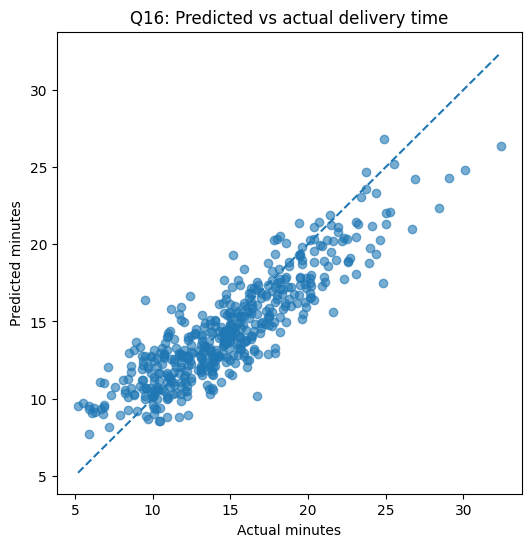

Largest errors:
 order_id  actual  predicted  absolute_error
DMO701211    24.8  17.507076        7.292924
DMO702174     9.5  16.366906        6.866906
DMO702191    16.7  10.187744        6.512256
DMO702109    28.4  22.338202        6.061798
DMO702377    32.4  26.380988        6.019012
DMO700134    21.6  15.585737        6.014263
DMO701566    26.7  20.992069        5.707931
DMO702150    30.1  24.785013        5.314987
DMO701751    23.9  18.803041        5.096959
DMO701644    24.4  19.363149        5.036851
MAE by rain:
raining
0    1.727809
1    1.862499
Peak-hour MAE: 1.7412
Other-hour MAE: 1.7612


In [19]:
# Q16
plt.figure(figsize=(6, 6))
plt.scatter(yte, pred_tuned, alpha=.6)
lo = min(yte.min(), pred_tuned.min())
hi = max(yte.max(), pred_tuned.max())
plt.plot([lo, hi], [lo, hi], linestyle="--")
plt.xlabel("Actual minutes")
plt.ylabel("Predicted minutes")
plt.title("Q16: Predicted vs actual delivery time")
plt.show()

test_meta = model_df.loc[Xte.index].copy()
test_meta["actual"] = yte
test_meta["predicted"] = pred_tuned
test_meta["absolute_error"] = abs(test_meta["actual"] - test_meta["predicted"])
print("Largest errors:")
print(test_meta.nlargest(10, "absolute_error")[
    ["order_id", "actual", "predicted", "absolute_error"]
].to_string(index=False))

print("MAE by rain:")
print(test_meta.groupby("raining").apply(
    lambda g: mean_absolute_error(g["actual"], g["predicted"])
).rename("MAE").to_string())

peak = test_meta["order_hour"].between(18, 21)
print("Peak-hour MAE:", round(mean_absolute_error(
    test_meta.loc[peak, "actual"], test_meta.loc[peak, "predicted"]
), 4) if peak.any() else "No peak-hour orders")
print("Other-hour MAE:", round(mean_absolute_error(
    test_meta.loc[~peak, "actual"], test_meta.loc[~peak, "predicted"]
), 4) if (~peak).any() else "No other-hour orders")


In [21]:
# Q17

buffer_rows = []
for buffer in [0, 2, 3, 4, 5]:
    late_share = (yte.to_numpy() > pred_tuned + buffer).mean()
    buffer_rows.append({
        "Buffer minutes": buffer,
        "Late share": late_share,
        "Late percent": late_share*100
    })
buffer_table = pd.DataFrame(buffer_rows)
print(buffer_table.round(4).to_string(index=False))
valid_buffers = buffer_table[buffer_table["Late share"] <= .10]
if len(valid_buffers):
    selected_buffer = int(valid_buffers.iloc[0]["Buffer minutes"])
    print("Smallest tested buffer with <=10% late:", selected_buffer)
else:
    selected_buffer = 5
    print("No tested buffer meets <=10%; 5 minutes is the largest tested buffer.")
print("Interpretation: select the smallest buffer that meets the late-order target, if any tested buffer does.")

 Buffer minutes  Late share  Late percent
              0      0.5992       59.9165
              2      0.2338       23.3820
              3      0.1086       10.8559
              4      0.0438        4.3841
              5      0.0209        2.0877
Smallest tested buffer with <=10% late: 4
Interpretation: select the smallest buffer that meets the late-order target, if any tested buffer does.


In [22]:
# Q18
new_order = pd.DataFrame([{
    "distance_km": 2.4,
    "items": 12,
    "order_value_rs": 1450,
    "store_queue": 11,
    "raining": 1,
    "rider_experience_months": 3,
    "drop_floor": 14,
    "hour_sin": np.sin(2*np.pi*20/24),
    "hour_cos": np.cos(2*np.pi*20/24)
}])[cyc_features]

new_prediction = float(best_model.predict(new_order)[0])
print("Predicted delivery minutes:", round(new_prediction, 2))
print("Promise including buffer:", round(new_prediction + selected_buffer, 2), "minutes")

Predicted delivery minutes: 23.83
Promise including buffer: 27.83 minutes


In [23]:
# Q19
pre = best_model.named_steps["scaler"]
knn = best_model.named_steps["knn"]
imputer = best_model.named_steps["imputer"]
Xtr_imputed = imputer.transform(Xtr)
Xtr_transformed = pre.transform(Xtr_imputed)
new_transformed = pre.transform(imputer.transform(new_order))
distances, indices = knn.kneighbors(
    new_transformed, n_neighbors=best_model.named_steps["knn"].n_neighbors
)
neighbor_rows = Xtr.iloc[indices[0]].copy()
neighbor_rows["actual_delivery_minutes"] = ytr.iloc[indices[0]].to_numpy()
neighbor_rows["distance"] = distances[0]
# Add hour back for readability
neighbor_rows["order_hour"] = (
    np.arctan2(neighbor_rows["hour_sin"], neighbor_rows["hour_cos"])
    * 24 / (2*np.pi)
) % 24
print(neighbor_rows[[
    "order_hour", "distance_km", "items", "store_queue",
    "raining", "actual_delivery_minutes", "distance"
]].to_string(index=False))
print("Interpretation: the estimate is fair if these orders resemble the new order on the main delay drivers.")

 order_hour  distance_km  items  store_queue  raining  actual_delivery_minutes  distance
       19.0         2.64      9         11.0        1                     28.4  1.737592
       18.0         1.60     10          9.0        1                     21.5  1.881321
       19.0         1.77     11         13.0        1                     23.9  2.061832
       18.0         1.23     13         11.0        1                     21.2  2.085331
       23.0         1.69     11          7.0        1                     22.3  2.390461
       17.0         2.44     10          7.0        1                     22.7  2.400471
       21.0         2.84      9         10.0        1                     26.1  2.418570
Interpretation: the estimate is fair if these orders resemble the new order on the main delay drivers.


In [24]:
# Q20

dry_order = new_order.copy()
dry_order["raining"] = 0
dry_prediction = float(best_model.predict(dry_order)[0])
print("Predicted in rain:", round(new_prediction, 2))
print("Predicted without rain:", round(dry_prediction, 2))
print("Rain-associated change (rain - dry):", round(new_prediction-dry_prediction, 2), "minutes")
print("Interpretation: a positive change is directionally plausible, but the estimate is an association learned from past orders.")

Predicted in rain: 23.83
Predicted without rain: 19.53
Rain-associated change (rain - dry): 4.3 minutes
Interpretation: a positive change is directionally plausible, but the estimate is an association learned from past orders.


In [25]:
# Q21
current_late_share = (yte.to_numpy() > 15).mean()
model_late_share = (yte.to_numpy() > pred_tuned + selected_buffer).mean()
savings_per_1000 = (current_late_share-model_late_share)*1000*50
print("Late share under 15-minute promise:", round(current_late_share*100, 2), "%")
print("Late share under model + buffer:", round(model_late_share*100, 2), "%")
print("Estimated coupon savings per 1,000 orders Rs:", round(savings_per_1000, 2))
print("Negative savings means the model would increase coupon cost at the chosen buffer.")

Late share under 15-minute promise: 43.63 %
Late share under model + buffer: 4.38 %
Estimated coupon savings per 1,000 orders Rs: 19624.22
Negative savings means the model would increase coupon cost at the chosen buffer.


In [26]:
# Q22
summary = pd.DataFrame([
    {"Model": "Median baseline", **baseline_metrics},
    {"Model": "Raw KNN", **metrics_raw},
    {"Model": "StandardScaler KNN", **metrics_std},
    {"Model": "Tuned cyclical KNN", **metrics_tuned},
    {"Model": "Tuned without order value", **metrics_no_value}
])
print(summary.round(4).to_string(index=False))

                    Model    MAE   RMSE      R2
          Median baseline 3.5186 4.5260 -0.0279
                  Raw KNN 3.7214 4.6703 -0.0945
       StandardScaler KNN 1.7264 2.1652  0.7648
       Tuned cyclical KNN 1.7554 2.2077  0.7554
Tuned without order value 1.7397 2.2057  0.7559


In [27]:
# Q23

print("1. Live traffic/road congestion: it changes travel time over short distances.")
print("2. Rider-to-store distance or rider availability: dispatch delay may be substantial before pickup.")
print("Other useful features could include packing time, weather severity, and actual dispatch time.")

1. Live traffic/road congestion: it changes travel time over short distances.
2. Rider-to-store distance or rider availability: dispatch delay may be substantial before pickup.
Other useful features could include packing time, weather severity, and actual dispatch time.


In [28]:
# Q24

print("KNN advantage: it can model local patterns among similar orders without assuming a linear relationship.")
print("Linear regression advantage: it is simpler and more interpretable, and can extrapolate more predictably under suitable assumptions.")
print("For a brand-new fifth store, I would initially trust a well-validated regression model more cautiously than KNN, because KNN has no nearby examples from that store. Neither should be deployed without validation.")

KNN advantage: it can model local patterns among similar orders without assuming a linear relationship.
Linear regression advantage: it is simpler and more interpretable, and can extrapolate more predictably under suitable assumptions.
For a brand-new fifth store, I would initially trust a well-validated regression model more cautiously than KNN, because KNN has no nearby examples from that store. Neither should be deployed without validation.


In [29]:
# Q25
print(f"""The tuned KNN model achieved test MAE {metrics_tuned['MAE']:.2f} minutes,
RMSE {metrics_tuned['RMSE']:.2f} minutes and R-squared {metrics_tuned['R2']:.3f}.
The MAE target under 2.5 minutes is {"met" if metrics_tuned["MAE"] < 2.5 else "not met"}.
The tested safety buffer selected was {selected_buffer} minutes; the measured late share with
that buffer was {model_late_share*100:.1f}%, so the 10% target is
{"met" if model_late_share <= .10 else "not met"}.
Estimated coupon savings per 1,000 orders are Rs {savings_per_1000:.0f}, assuming each late
order costs Rs 50 and the test set is representative.
The main limitation is that this dataset covers only one month and four stores, so traffic,
staffing changes, unusual weather, and a new store may make future predictions less reliable.""")

# Download cleaned CSV
files.download(clean_b_path)

The tuned KNN model achieved test MAE 1.76 minutes,
RMSE 2.21 minutes and R-squared 0.755.
The MAE target under 2.5 minutes is met.
The tested safety buffer selected was 4 minutes; the measured late share with
that buffer was 4.4%, so the 10% target is
met.
Estimated coupon savings per 1,000 orders are Rs 19624, assuming each late
order costs Rs 50 and the test set is representative.
The main limitation is that this dataset covers only one month and four stores, so traffic,
staffing changes, unusual weather, and a new store may make future predictions less reliable.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>